# 12 — AMX ablations: what does AMX contribute?

**Objective.** Replace two inferences of the earlier notebooks by measurements: that AMX is what lets vLLM scale (notebook 06) and that
llama.cpp's AMX path is inefficient (notebook 08, section 3).

**Research questions.**
1. (T3.1) What do the vLLM ablation levels really switch off, and how do throughput and scaling change without AMX?
2. (T3.2) Does llama.cpp's AMX build run Q8_0 prompt processing faster than its AVX-512 build, and how much of the AMX roof does it reach?

**Data.** `online/amx-ablation-verify` (short points per vLLM level with `ONEDNN_VERBOSE=profile_create`: `EXE.AMX_BUSY` and the oneDNN
implementations created) and `offline/amx-build` (llama-bench prompt processing of Q8_0, 8B, prompt lengths 128, 512, 4096, 8192; AMX build and
AVX-512 build, order amx, avx512, amx, avx512 inside one job, three llama-bench samples per cell). The two llama.cpp builds are configured
identically except `GGML_AMX_TILE/INT8/BF16` (`build-avx512/CMakeCache.txt`).

**Method.** The ratio AMX ÷ AVX-512 is formed inside each pass pair. Arithmetic rates use the operation model of notebook 10 (modelled operations per prompt
token × tokens/s) and are compared with the measured AMX INT8 GEMM roof. `EXE.AMX_BUSY` ÷ cycles is read from the telemetry samples in which the server cores
were busy.

**Assumptions.** llama-bench times forward passes only (no server). Prompt processing is the phase in which AMX can help most; decode and batched serving were not run
with the AVX-512 build.

In [1]:
import pandas as pd
from IPython.display import display

from llm_backend_analysis import paths
from llm_backend_analysis.analysis import amx, roofline
from llm_backend_analysis.data import loaders, registry
from llm_backend_analysis.reporting import Claim, claims_table, export_table, num, pct, rng, show, table, x
from llm_backend_analysis.visualization import plots, theme
from llm_backend_analysis.visualization.export import export_figure

theme.setup_notebook()
NOTEBOOK = "12_amx_ablations.ipynb"
compute = roofline.compute_ceilings(loaders.hardware_ceilings())

## 1. What do the vLLM ablation levels switch off?

`ONEDNN_MAX_CPU_ISA=AVX512_CORE_BF16` caps oneDNN's GEMMs below AMX, but vLLM also has its own AMX code (an attention kernel and small-weight linear kernels) that
does not look at that variable; it asks `torch.cpu._is_amx_tile_supported()`. Level `noamx_all` makes torch answer False. Each level was run for one short balanced
(512→512) point at C = 1 and C = 8.

In [2]:
ver = amx.verify_table(paths.RAW / "online" / "amx-ablation-verify" / "amx_verify.json")
display(table(ver.rename(columns={"level": "Level", "concurrency": "C", "status": "Status", "amx_busy_frac": "EXE.AMX_BUSY ÷ cycles",
                                  "no_amx_shim_active": "torch reports no AMX", "matmul_implementations": "oneDNN matmul implementations created",
                                  "amx_primitives": "AMX primitives"}),
              {"EXE.AMX_BUSY ÷ cycles": "{:.4%}"}, align="left"))
v = ver.set_index(["level", "concurrency"])
show(f"With AMX allowed vLLM's oneDNN matmuls are `brg_matmul:avx10_1_512_amx` and the AMX unit is busy {pct(v.loc[('amx', 1), 'amx_busy_frac'], 2, False)} (C = 1) to "
     f"{pct(v.loc[('amx', 8), 'amx_busy_frac'], 2, False)} (C = 8) of the cycles. Capping oneDNN removes every AMX matmul "
     f"(`brg_matmul:avx512_core_bf16`) and cuts the busy fraction by {pct(1 - v.loc[('noamx_gemm', 8), 'amx_busy_frac'] / v.loc[('amx', 8), 'amx_busy_frac'], 1, False)} at C = 8, "
     f"but not to zero ({pct(v.loc[('noamx_gemm', 8), 'amx_busy_frac'], 3, False)}): what remains is vLLM's own AMX code. With torch also reporting no AMX the counter reads "
     f"{pct(v.loc[('noamx_all', 8), 'amx_busy_frac'], 1, False)} at both C.")

Level,C,Status,EXE.AMX_BUSY ÷ cycles,torch reports no AMX,oneDNN matmul implementations created,AMX primitives
amx,1,ok,0.4895%,False,brg_matmul:avx10_1_512_amx ×14,14
amx,8,ok,1.9580%,False,brg_matmul:avx10_1_512_amx ×81,81
noamx_gemm,1,ok,0.0068%,False,brg_matmul:avx512_core_bf16 ×14,0
noamx_gemm,8,ok,0.0206%,False,brg_matmul:avx512_core_bf16 ×77,0
noamx_all,1,ok,0.0000%,True,brg_matmul:avx512_core_bf16 ×14,0
noamx_all,8,ok,0.0000%,True,brg_matmul:avx512_core_bf16 ×73,0


With AMX allowed vLLM's oneDNN matmuls are `brg_matmul:avx10_1_512_amx` and the AMX unit is busy 0.49% (C = 1) to 1.96% (C = 8) of the cycles. Capping oneDNN removes every AMX matmul (`brg_matmul:avx512_core_bf16`) and cuts the busy fraction by 98.9% at C = 8, but not to zero (0.021%): what remains is vLLM's own AMX code. With torch also reporting no AMX the counter reads 0.0% at both C.

**Interpretation.** `noamx_gemm` is the setting of the review but leaves a small AMX residue; `noamx_all` is a complete AMX ablation for the BF16 paths that matter here
(the counter is exactly zero). Comparing the two levels apportions any loss between oneDNN's GEMMs and vLLM's own AMX kernels.

## 2. llama.cpp Q8_0: AMX build vs AVX-512 build (prompt processing)

Does the AMX path of llama.cpp make prompt processing faster at all, and by how much?

Prompt tokens,AVX-512 build tok/s,AMX build tok/s,AMX ÷ AVX-512,pair min,pair max,AVX-512 ÷ AMX INT8 roof,AMX build ÷ AMX INT8 roof,"AMX busy, AVX-512 build","AMX busy, AMX build"
128,241,364,1.51×,1.50×,1.51×,3.8%,5.8%,0.00%,3.99%
512,217,426,1.96×,1.94×,1.98×,3.5%,6.8%,0.00%,4.56%
4096,186,454,2.44×,2.43×,2.44×,3.2%,7.7%,0.00%,5.14%
8192,170,349,2.05×,2.05×,2.06×,3.1%,6.4%,0.00%,4.12%


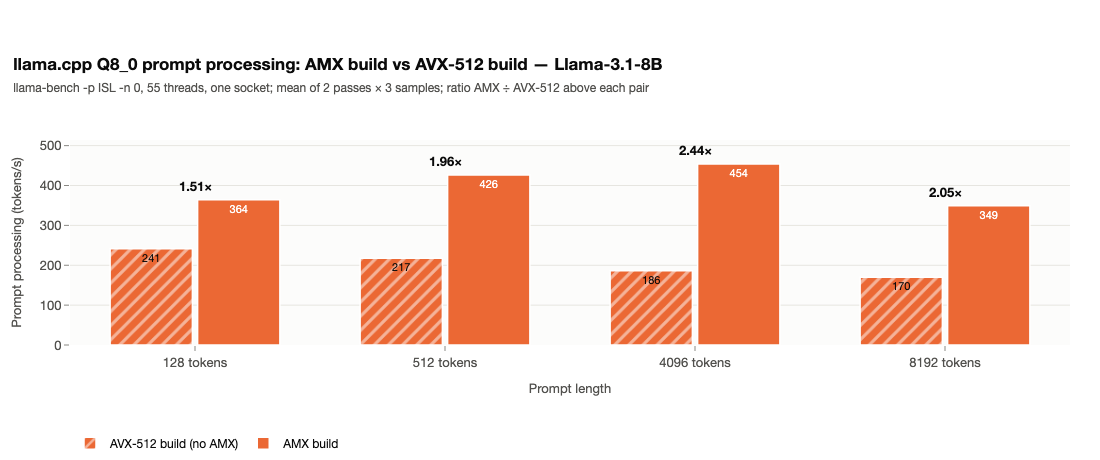

The AMX build processes prompts 1.51×–2.44× as fast as the AVX-512 build (largest at 4096 tokens); the ratio of a pass pair stays within ±0.8% of the mean. The AMX unit is busy 4.0%–5.1% of the cycles with the AMX build and 0.0% with the AVX-512 build. The AMX build reaches 5.8%–7.7% of the measured AMX INT8 GEMM roof (88.3 TOP/s), the AVX-512 build 3.1%–3.8%.

In [3]:
samples = loaders.offline_samples(campaign="amx-build")
cmp = amx.build_comparison(samples, compute)
busy = amx.offline_amx_busy(paths.RAW / "telemetry", "amx-build").groupby(["workload", "build"])["amx_busy_frac"].mean().unstack()
cmp = cmp.merge(busy.rename(columns={"amx": "amx_busy_amx_build", "avx512": "amx_busy_avx512_build"}), left_on="workload", right_index=True)
display(table(cmp[["isl", "avx512_tok_s", "amx_tok_s", "ratio", "ratio_min", "ratio_max", "avx512_share_of_roof", "amx_share_of_roof",
                   "amx_busy_avx512_build", "amx_busy_amx_build"]]
              .rename(columns={"isl": "Prompt tokens", "avx512_tok_s": "AVX-512 build tok/s", "amx_tok_s": "AMX build tok/s", "ratio": "AMX ÷ AVX-512",
                               "ratio_min": "pair min", "ratio_max": "pair max", "avx512_share_of_roof": "AVX-512 ÷ AMX INT8 roof",
                               "amx_share_of_roof": "AMX build ÷ AMX INT8 roof", "amx_busy_avx512_build": "AMX busy, AVX-512 build",
                               "amx_busy_amx_build": "AMX busy, AMX build"}),
              {"AVX-512 build tok/s": "{:.0f}", "AMX build tok/s": "{:.0f}", "AMX ÷ AVX-512": "{:.2f}×", "pair min": "{:.2f}×", "pair max": "{:.2f}×",
               "AVX-512 ÷ AMX INT8 roof": "{:.1%}", "AMX build ÷ AMX INT8 roof": "{:.1%}", "AMX busy, AVX-512 build": "{:.2%}",
               "AMX busy, AMX build": "{:.2%}"}))
fig = plots.build_comparison_figure(cmp, title="llama.cpp Q8_0 prompt processing: AMX build vs AVX-512 build — Llama-3.1-8B",
                                    subtitle="llama-bench -p ISL -n 0, 55 threads, one socket; mean of 2 passes × 3 samples; ratio AMX ÷ AVX-512 above each pair")
fig.show()
export_figure(fig, "amx_build_prompt_processing", source=NOTEBOOK,
              caption="llama.cpp Q8_0 (8B) prompt processing with the AMX build (solid) and the AVX-512 build (hatched), by prompt length; ratio above each pair.")
export_table(cmp, "amx_build_comparison")
show(f"The AMX build processes prompts {rng(cmp['ratio'], x, nd=2)} as fast as the AVX-512 build (largest at {int(cmp.loc[cmp['ratio'].idxmax(), 'isl'])} tokens); the ratio of a pass "
     f"pair stays within ±{pct(max((cmp['ratio_min'] / cmp['ratio'] - 1).abs().max(), (cmp['ratio_max'] / cmp['ratio'] - 1).abs().max()), 1, False)} of the mean. "
     f"The AMX unit is busy {rng(cmp['amx_busy_amx_build'], lambda v: pct(v, 1, False))} of the cycles with the AMX build and {pct(cmp['amx_busy_avx512_build'].max(), 1, False)} with the AVX-512 build. "
     f"The AMX build reaches {rng(cmp['amx_share_of_roof'], lambda v: pct(v, 1, False))} of the measured AMX INT8 GEMM roof ({num(cmp['roof_tops'].iloc[0], 1)} TOP/s), the AVX-512 build "
     f"{rng(cmp['avx512_share_of_roof'], lambda v: pct(v, 1, False))}.")

**Interpretation.** *Measured:* llama.cpp's AMX path is effective in the sense that it makes Q8_0 prompt processing 1.5–2.4× faster than the AVX-512 kernels of the same engine,
and the effect grows with the prompt length where more rows fill the tiles. *Also measured:* it uses little of what the hardware offers, a few percent of the AMX INT8 GEMM roof with the
AMX unit busy only 4–5% of the cycles, so the AMX build lifts the engine from AVX-512 level but not to the hardware's level (the correction of notebook 08, section 3, stands:
"AMX available" is not "AMX used efficiently"). *Not measured here:* the reason (tile loading, packing, thread scaling) and the effect on decode or batched serving.

In [4]:
claims = [
    Claim("The AMX build is faster than the AVX-512 build at every prompt length", bool((cmp["ratio"] > 1).all()), rng(cmp["ratio"], x, nd=2)),
    Claim("The AMX build keeps the AMX unit busy; the AVX-512 build does not touch it",
          bool((cmp["amx_busy_amx_build"] > 0.01).all() and (cmp["amx_busy_avx512_build"] < 0.001).all()),
          f"AMX build {rng(cmp['amx_busy_amx_build'], lambda v: pct(v, 1, False))}, AVX-512 build {pct(cmp['amx_busy_avx512_build'].max(), 2, False)}"),
    Claim("Both passes agree: the ratio of each pass pair is within 3% of the mean", bool(((cmp["ratio_max"] - cmp["ratio_min"]) / cmp["ratio"] < 0.03).all()),
          f"largest spread {pct(((cmp['ratio_max'] - cmp['ratio_min']) / cmp['ratio']).max(), 1, False)}"),
    Claim("Even with AMX the build reaches under 10% of the AMX INT8 GEMM roof", bool((cmp["amx_share_of_roof"] < 0.10).all()),
          rng(cmp["amx_share_of_roof"], lambda v: pct(v, 1, False))),
    Claim("The AMX gain is larger at 512 and 4096 tokens than at 128", bool(cmp.set_index("isl").loc[[512, 4096], "ratio"].min() > cmp.set_index("isl").loc[128, "ratio"]),
          "ratios by prompt length above"),
]
display(claims_table(claims))

Holds,Statement,Evidence (computed)
✓,The AMX build is faster than the AVX-512 build at every prompt length,1.51×–2.44×
✓,The AMX build keeps the AMX unit busy; the AVX-512 build does not touch it,"AMX build 4.0%–5.1%, AVX-512 build 0.00%"
✓,Both passes agree: the ratio of each pass pair is within 3% of the mean,largest spread 1.6%
✓,Even with AMX the build reaches under 10% of the AMX INT8 GEMM roof,5.8%–7.7%
✓,The AMX gain is larger at 512 and 4096 tokens than at 128,ratios by prompt length above


## Conclusions

- **Measured (T3.1, verification):** the three vLLM levels do what they claim: AMX allowed (oneDNN `brg_matmul:avx10_1_512_amx`), oneDNN capped (no AMX matmul, a small residue from vLLM's own
  kernels), every AMX path off (counter exactly zero).
- **Measured (T3.2):** llama.cpp's AMX build processes Q8_0 prompts 1.5–2.4× faster than its AVX-512 build while reaching only a few percent of the AMX INT8 roof.
- **Interpretation:** AMX is not wasted in llama.cpp but is far from saturated, consistent with "kernel efficiency, not AMX availability" as the engine difference of notebooks 06 and 08.

## Limitations

- Prompt processing only, one model (8B), two passes of three samples; no decode, no batched or served runs with the AVX-512 build.
- The AVX-512 build has the same source and flags apart from AMX; the check is the CMake cache, not the binaries' hashes.
- The vLLM ablation sweeps (T3.1) are not in this notebook yet; only the verification of the levels is.